In [ ]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn import metrics, preprocessing

data = pd.read_csv('prix_maisons2.csv')
data.isna().sum()


In [ ]:
median = data['rooms'].median()
print(median)

In [ ]:
data['rooms'] = data['rooms'].fillna(median)
# encoder les valeurs (linearReg use numbers)
encoder = preprocessing.LabelEncoder()
data['city_label'] = encoder.fit_transform(data['city'])

### data visualisation


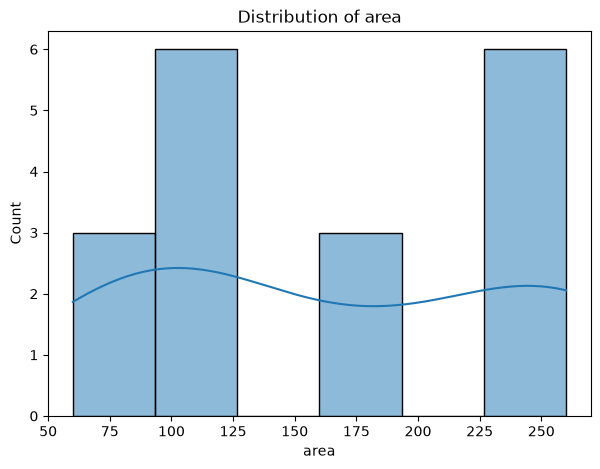

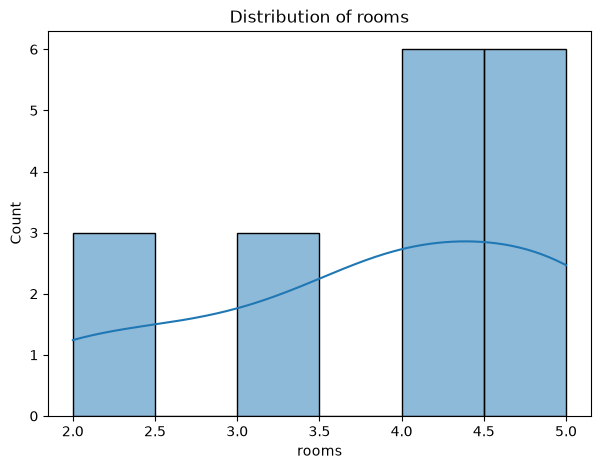

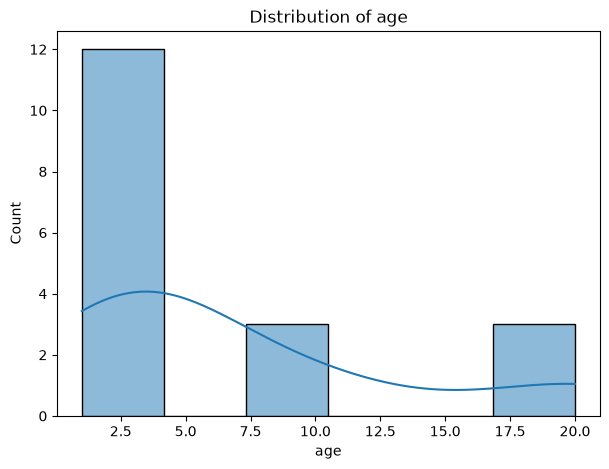

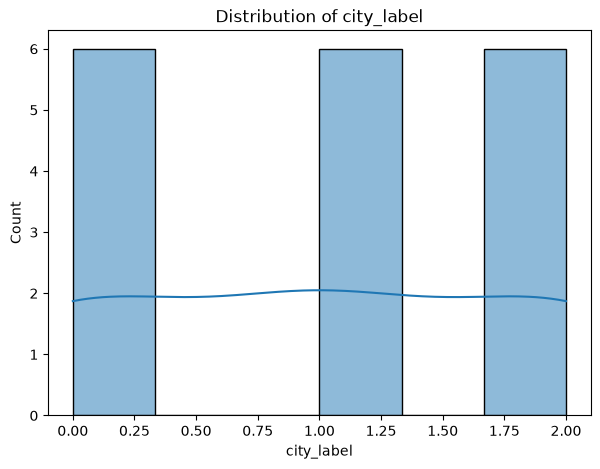

In [34]:
import seaborn as sn
y = data['price']
X = data.drop(columns=['price', 'city'])

for col in X.columns:
    plt.figure(figsize=(7,5))
    plt.title(f'Distribution of {col}')
    sn.histplot(data[col], kde=True)
    plt.show()


### La matrice de correlation

In [ ]:
plt.figure(figsize=(7,5))
plt.title('Matrix of correlation')
sn.heatmap(X.corr(), annot=True, cmap='coolwarm', fmt='.2f')

### entrainement du modele


In [ ]:

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train.shape , X_test.shape #, y_train.shape, y_test.shape

In [ ]:
model = LinearRegression()

model.fit(X_train, y_train)

In [ ]:
predictions_test = model.predict(X_test)
predictions_train = model.predict(X_train)

metrics.r2_score(y_test, predictions_test), metrics.r2_score(y_train, predictions_train)

### verification par la lib et par l'equation de la droite de regression

In [ ]:
price1 = model.predict([[100, 3, 1, 1]]) 
coef = model.coef_
intercept = model.intercept_
price2 = coef[0]*100 + coef[1]*3 + coef[2]*1 + coef[3]*1 + intercept

print(f'Price1: {price1}, Price2: {price2}')

### Métriques d'évaluation

**1. MAE (Mean Absolute Error) :**
$$MAE = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|$$

**2. MSE (Mean Squared Error) :**
$$MSE = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

**3. RMSE (Root Mean Squared Error) :**
$$RMSE = \sqrt{\frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2}$$

**4. Coefficient de détermination ($R^2$) :**
$$R^2 = 1 - \frac{\sum_{i=1}^{n} (y_i - \hat{y}_i)^2}{\sum_{i=1}^{n} (y_i - \bar{y})^2}$$
